# CS232 — Handwritten Math OCR → LaTeX
Notebook thử nghiệm **MathWriting + CNN encoder + Transformer decoder**. Chạy trên Kaggle/Colab GPU. Đây là baseline huấn luyện từ đầu, **không đảm bảo nhận dạng tốt công thức phức tạp khi chỉ train ít epoch**. Notebook có walkthrough một data point, train, evaluate và inference.

## 0. Cài đặt và cấu hình

In [19]:
%pip -q install datasets pillow matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.


In [20]:
import os, re, math, random, copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from tqdm.auto import tqdm
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## 1. Tải dataset và kiểm tra schema
Tên cột của các bản dataset có thể thay đổi. Cell này hiển thị schema thật trước khi ánh xạ.

In [21]:
DATASET_ID="deepcopy/MathWriting-human"
raw=load_dataset(DATASET_ID)
print(raw)
print(raw[list(raw.keys())[0]].features)
print({k:type(v).__name__ for k,v in raw[list(raw.keys())[0]][0].items()})

DatasetDict({
    train: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 229864
    })
    test: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 7644
    })
    val: Dataset({
        features: ['image', 'latex', 'sample_id', 'split_tag', 'data_type'],
        num_rows: 15674
    })
})
{'image': Image(mode=None, decode=True), 'latex': Value('string'), 'sample_id': Value('string'), 'split_tag': Value('string'), 'data_type': Value('string')}
{'image': 'JpegImageFile', 'latex': 'str', 'sample_id': 'str', 'split_tag': 'str', 'data_type': 'str'}


Columns: ['image', 'latex', 'sample_id', 'split_tag', 'data_type']
{'latex': 'V(\\tilde{\\beta})', 'sample_id': '47f7bccab32dc3b3', 'split_tag': 'train', 'data_type': 'human'}
Detected: image latex


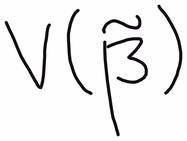

V(\tilde{\beta})


In [22]:
split_names=list(raw.keys()); train_key="train" if "train" in raw else split_names[0]
row=raw[train_key][0]
print("Columns:",list(row))
print({k:str(v)[:160] for k,v in row.items() if not isinstance(v,Image.Image)})
IMAGE_COL=next((k for k,v in row.items() if isinstance(v,Image.Image)),None)
LABEL_COL=next((k for k in ["latex","label","formula","text","normalized_latex"] if k in row and isinstance(row[k],str)),None)
print("Detected:",IMAGE_COL,LABEL_COL)
assert IMAGE_COL and LABEL_COL, "Schema khác dự kiến: hãy xem columns và chỉnh IMAGE_COL / LABEL_COL"
display(row[IMAGE_COL]); print(row[LABEL_COL])

## 2. Tiền xử lý ảnh
Resize giữ tỷ lệ, nền trắng và nét đen; tensor đầu ra `[1, H, W]` có nét sáng trên nền tối. Không phân đoạn ký tự, vì công thức có bố cục 2D.

torch.Size([1, 96, 384]) 0.0 1.0


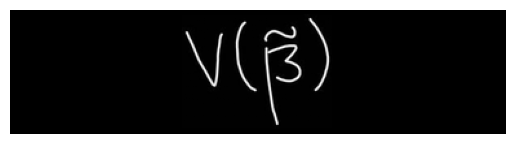

In [23]:
HEIGHT,WIDTH=96,384
def preprocess(img, size=(HEIGHT,WIDTH)):
    h,w=size
    im=img.convert("L")
    im=ImageOps.autocontrast(im)
    a=np.asarray(im)
    # Giả định nền sáng, nét tối; đảo nếu ảnh có nền tối
    if a.mean()<127: im=ImageOps.invert(im)
    im.thumbnail((w-8,h-8),Image.Resampling.LANCZOS)
    canvas=Image.new("L",(w,h),255)
    canvas.paste(im,((w-im.width)//2,(h-im.height)//2))
    return torch.from_numpy((1-np.asarray(canvas,dtype=np.float32)/255)[None].copy())
x=preprocess(row[IMAGE_COL]); print(x.shape,x.min().item(),x.max().item())
plt.imshow(x[0],cmap="gray"); plt.axis("off"); plt.show()

## 3. Tokenizer LaTeX tự viết
Dùng lệnh `\command` là một token, còn ký tự và dấu ngoặc là token riêng. Không xóa dấu ngoặc vì cần cấu trúc lồng nhau.

In [24]:
PATTERN=re.compile(r"\\[a-zA-Z]+|\\.|[^\s]")
def tokenize(s):return PATTERN.findall(s)
print(tokenize(r"\frac{x^2}{y+1}"))
SPECIAL=["<pad>","<bos>","<eos>","<unk>"]
MAX_SAMPLES=12000  # giảm để chạy thử; tăng khi có GPU và thời gian
MAX_LEN=128
train_data=raw[train_key].shuffle(seed=SEED).select(range(min(MAX_SAMPLES,len(raw[train_key]))))
from collections import Counter
cnt=Counter(t for s in train_data[LABEL_COL] for t in tokenize(s))
vocab=SPECIAL+[t for t,c in sorted(cnt.items()) if c>=2 and t not in SPECIAL]
stoi={s:i for i,s in enumerate(vocab)}; itos={i:s for s,i in stoi.items()}
PAD,BOS,EOS,UNK=[stoi[t] for t in SPECIAL]
def encode(s):return [BOS]+[stoi.get(t,UNK) for t in tokenize(s)][:MAX_LEN-2]+[EOS]
def decode(ids):
    out=[]
    for i in ids:
        i=int(i)
        if i==EOS:break
        if i not in (PAD,BOS):out.append(itos.get(i,"?"))
    return "".join(out)
print("vocab",len(vocab),"example",encode(row[LABEL_COL])[:30])

['\\frac', '{', 'x', '^', '2', '}', '{', 'y', '+', '1', '}']
vocab 210 example [1, 51, 6, 159, 207, 76, 209, 7, 2]


## 4. Dataset và split
Nếu dataset không có validation, chia **từ train**. Không sử dụng test để chọn hyperparameter.

In [25]:
if "validation" in raw:
    val_data=raw["validation"]
elif "val" in raw:
    val_data=raw["val"]
else:
    parts=train_data.train_test_split(test_size=.1,seed=SEED)
    train_data,val_data=parts["train"],parts["test"]
val_data=val_data.select(range(min(1000,len(val_data))))
class MathDS(Dataset):
    def __init__(self,ds):self.ds=ds
    def __len__(self):return len(self.ds)
    def __getitem__(self,i):
        r=self.ds[i]; return preprocess(r[IMAGE_COL]),torch.tensor(encode(r[LABEL_COL]),dtype=torch.long)
def collate(batch):
    imgs,seqs=zip(*batch); maxlen=max(len(s) for s in seqs)
    y=torch.full((len(seqs),maxlen),PAD,dtype=torch.long)
    for i,s in enumerate(seqs):y[i,:len(s)]=s
    return torch.stack(imgs),y
BATCH=16
train_loader=DataLoader(MathDS(train_data),batch_size=BATCH,shuffle=True,collate_fn=collate,num_workers=0)
val_loader=DataLoader(MathDS(val_data),batch_size=BATCH,collate_fn=collate,num_workers=0)
print(len(train_data),len(val_data))

12000 1000


## 5. CNN + 2D positional encoding + Transformer
Giảm kích thước không gian 16 lần → với ảnh 96×384 có 6×24=144 encoder tokens. Decoder sinh token LaTeX tuần tự.

In [26]:
class MathOCR(nn.Module):
    def __init__(self, vocab_size, d=192):
        super().__init__()
        assert d % 4 == 0, "d phải chia hết cho 4"
        self.d = d

        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, d, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.emb = nn.Embedding(
            vocab_size, d, padding_idx=PAD
        )

        self.dec = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(
                d_model=d,
                nhead=4,
                dim_feedforward=384,
                dropout=0.1,
                batch_first=True
            ),
            num_layers=2
        )

        self.out = nn.Linear(d, vocab_size)

    def positional(self, length, dim, device):
        assert dim % 2 == 0

        pos = torch.arange(
            length, device=device, dtype=torch.float32
        ).unsqueeze(1)

        freq = torch.exp(
            torch.arange(
                0, dim, 2,
                device=device,
                dtype=torch.float32
            ) * (-math.log(10000.0) / dim)
        )

        pe = torch.zeros(length, dim, device=device)
        pe[:, 0::2] = torch.sin(pos * freq)
        pe[:, 1::2] = torch.cos(pos * freq)

        return pe

    def encode_image(self, x):
        f = self.cnn(x)
        b, d, h, w = f.shape

        rh = self.positional(
            h, d // 2, f.device
        )[:, None, :].expand(h, w, -1)

        cw = self.positional(
            w, d // 2, f.device
        )[None, :, :].expand(h, w, -1)

        p = torch.cat(
            [rh, cw], dim=-1
        ).reshape(1, h * w, d)

        memory = f.flatten(2).transpose(1, 2)
        return memory + p.to(dtype=memory.dtype)

    def forward(self, x, tokens):
        mem = self.encode_image(x)

        b, t = tokens.shape

        z = self.emb(tokens)

        pe = self.positional(
            t, self.d, tokens.device
        ).unsqueeze(0)

        z = z + pe.to(dtype=z.dtype)

        # Causal mask: không nhìn token tương lai
        mask = torch.triu(
            torch.ones(
                t, t,
                device=tokens.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Mask token padding
        padding_mask = tokens.eq(PAD)

        # Tránh hàng bị mask hoàn toàn
        # khi một mẫu chỉ chứa PAD
        all_pad = padding_mask.all(dim=1)
        if all_pad.any():
            padding_mask = padding_mask.clone()
            padding_mask[all_pad, 0] = False

        z = self.dec(
            tgt=z,
            memory=mem,
            tgt_mask=mask,
            tgt_key_padding_mask=padding_mask
        )

        return self.out(z)


# Khởi tạo model
model = MathOCR(len(vocab)).to(device)

# Kiểm tra forward
xb, yb = next(iter(train_loader))

x = xb[:2].to(device)
tokens = yb[:2, :-1].to(device)

with torch.no_grad():
    logits = model(x, tokens)
    memory = model.encode_image(x)

print("Image:", tuple(x.shape))
print("Tokens:", tuple(tokens.shape))
print("Memory:", tuple(memory.shape))
print("Logits:", tuple(logits.shape))

assert logits.shape == (
    x.shape[0],
    tokens.shape[1],
    len(vocab)
)

print("Forward pass OK!")

Image: (2, 1, 96, 384)
Tokens: (2, 33)
Memory: (2, 144, 192)
Logits: (2, 33, 210)
Forward pass OK!


## 6. Walkthrough một data point
Quan sát nhãn, token IDs, ảnh, feature shape, decoder input/target, logits và loss thực tế trước khi train.

Ground truth: \Delta x_{meas}(t_{j+1})
Tokens: ['\\Delta', 'x', '_', '{', 'm', 'e', 'a', 's', '}', '(', 't', '_', '{', 'j', '+', '1', '}', ')']
IDs: [1, 59, 204, 180, 207, 193, 185, 181, 199, 209, 6, 200, 180, 207, 190, 9, 15, 209, 7, 2]


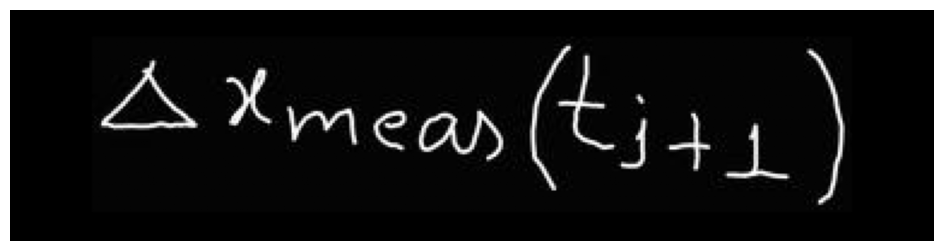

image: (1, 96, 384) encoder: (1, 144, 192) decoder input: [1, 59, 204, 180, 207, 193, 185, 181, 199, 209, 6, 200, 180, 207, 190, 9, 15, 209, 7]
target: [59, 204, 180, 207, 193, 185, 181, 199, 209, 6, 200, 180, 207, 190, 9, 15, 209, 7, 2] logits: (1, 19, 210) untrained loss: 5.217040061950684
first-token top5: [('\\ne', 0.0138), ('\\sum', 0.0132), ('\\nu', 0.0131), ('\\bigcap', 0.0127), ('\\bigoplus', 0.0122)]


In [27]:
img, ids = MathDS(train_data)[0]

print("Ground truth:", train_data[0][LABEL_COL])
print("Tokens:", tokenize(train_data[0][LABEL_COL]))
print("IDs:", ids.tolist())

plt.figure(figsize=(12, 3))
plt.imshow(img[0], cmap="gray")
plt.axis("off")
plt.show()

with torch.no_grad():
    memory = model.encode_image(img[None].to(device))
    scores = model(
        img[None].to(device),
        ids[None, :-1].to(device)
    )

    loss = nn.functional.cross_entropy(
        scores.reshape(-1, len(vocab)),
        ids[1:].to(device),
        ignore_index=PAD
    )

print(
    "image:", tuple(img.shape),
    "encoder:", tuple(memory.shape),
    "decoder input:", ids[:-1].tolist()
)

print(
    "target:", ids[1:].tolist(),
    "logits:", tuple(scores.shape),
    "untrained loss:", float(loss)
)

# FIX: Chuyển Tensor thành int bằng .item()
probs = torch.softmax(scores[0, 0], dim=-1)
top_probs, top_indices = probs.topk(5)

print("first-token top5:", [
    (itos[i.item()], round(v.item(), 4))
    for v, i in zip(top_probs, top_indices)
])

## 7. Huấn luyện
Thử overfit 16–32 mẫu trước khi tăng dữ liệu. Mặc định 5 epochs chỉ là smoke test; mô hình OCR đầy đủ thường cần huấn luyện lâu hơn.

In [28]:
EPOCHS=5
opt=torch.optim.AdamW(model.parameters(),lr=3e-4)
criterion=nn.CrossEntropyLoss(ignore_index=PAD)
def run_epoch(loader,train=False):
    model.train(train); total=0;count=0
    for x,y in tqdm(loader,leave=False):
        x,y=x.to(device),y.to(device)
        with torch.set_grad_enabled(train):
            out=model(x,y[:,:-1]);loss=criterion(out.reshape(-1,len(vocab)),y[:,1:].reshape(-1))
            if train:
                opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);opt.step()
        total+=float(loss.detach())*len(x);count+=len(x)
    return total/max(count,1)
best=float("inf")
for epoch in range(EPOCHS):
    tr=run_epoch(train_loader,True);va=run_epoch(val_loader)
    print(f"Epoch {epoch+1}: train={tr:.4f}, val={va:.4f}")
    if va<best:
        best=va;torch.save({"model":model.state_dict(),"vocab":vocab,"config":{"height":HEIGHT,"width":WIDTH,"d":192}},"mathocr_best.pt")

  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 1: train=2.3153, val=2.0741


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

...

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 4: train=1.6120, val=1.6576


  0%|          | 0/750 [00:00<?, ?it/s]

  0%|          | 0/63 [00:00<?, ?it/s]

Epoch 5: train=1.4984, val=1.5660


## 8. Inference và đánh giá
Exact-match chuỗi LaTeX rất nghiêm ngặt: hai cách viết tương đương có thể bị tính sai. Đánh giá thêm normalized edit distance.

In [29]:
@torch.no_grad()
def predict(img,max_tokens=MAX_LEN):
    model.eval(); x=preprocess(img)[None].to(device); mem=model.encode_image(x)
    seq=torch.tensor([[BOS]],device=device)
    for _ in range(max_tokens-1):
        t=seq.shape[1];z=model.emb(seq)+model.positional(t,model.d,device)[None]
        mask=torch.triu(torch.ones(t,t,device=device,dtype=torch.bool),diagonal=1)
        logits=model.out(model.dec(z,mem,tgt_mask=mask))
        nxt=logits[:,-1].argmax(-1,keepdim=True);seq=torch.cat([seq,nxt],dim=1)
        if nxt.item()==EOS:break
    return decode(seq[0].tolist())
if os.path.exists("mathocr_best.pt"):
    ckpt=torch.load("mathocr_best.pt",map_location=device,weights_only=False);model.load_state_dict(ckpt["model"])
for i in range(min(5,len(val_data))):
    r=val_data[i];print("GOLD:",r[LABEL_COL],"\nPRED:",predict(r[IMAGE_COL]),"\n")

GOLD: \frac{\partial\psi}{\partial t}=P\psi 
PRED: \frac{\partialf}{\partialt}=0 

GOLD: C_{0}=D/V_{blood} 
PRED: C=\int_{0}^{\infty}f(x)dx 

GOLD: e^{2}/\hbar c\approx1/137 
PRED: e^{i(i)}(i,i)=i(i) 

GOLD: nassoc(S,\overline{S}) 
PRED: p(x)=(x) 

GOLD: Eq.1\frac{dV}{dx}=w 
PRED: E=\frac{dV}{dt}=\frac{dV}{dt} 



In [30]:
def edit_distance(a,b):
    prev=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        cur=[i]+[0]*len(b)
        for j,cb in enumerate(b,1):cur[j]=min(cur[j-1]+1,prev[j]+1,prev[j-1]+(ca!=cb))
        prev=cur
    return prev[-1]
def evaluate(n=100):
    exact=[];ned=[]
    for i in tqdm(range(min(n,len(val_data)))):
        r=val_data[i];gold=r[LABEL_COL];pred=predict(r[IMAGE_COL])
        exact.append(pred==gold);ned.append(edit_distance(tokenize(pred),tokenize(gold))/max(1,len(tokenize(pred)),len(tokenize(gold))))
    print("Exact match:",np.mean(exact),"Mean normalized edit distance:",np.mean(ned))
evaluate(100)

  0%|          | 0/100 [00:00<?, ?it/s]

Exact match: 0.02 Mean normalized edit distance: 0.6581333295998233


## 9. Lưu ý cho đồ án
- Không cam kết hỗ trợ mọi ký hiệu chỉ vì kiến trúc có khả năng sinh LaTeX. Chỉ công bố các nhóm đã kiểm tra.
- Tập con 12k và 5 epochs chủ yếu kiểm thử pipeline. Muốn kết quả tốt cần GPU, nhiều dữ liệu, tuning và phân tích lỗi.
- Một số bản MathWriting có định dạng nhãn khác; cell schema giúp phát hiện trước.
- Sau khi có checkpoint tốt, có thể dùng Streamlit gọi `predict()` và `st.latex()`.
- Bước mở rộng: beam search, augmentation, kiểm tra cú pháp LaTeX, so sánh baseline pretrained.